# **Development Notebook - Match Analysis**
### **Updated as of 10/24/26**
The following notebook was used in the development process of the dashboard. It currently includes the creation of the datasets used in the app and the visualizations for the match analysis portion of the dashboard. The Team and Player Analysis sections of the application are currently being worked on and this notebook will be updated to reflect those changes when available


In [1]:
from statsbombpy import sb
import matplotlib.patheffects as path_effects
import pandas as pd
import numpy as np
import getpass as gp
import warnings
import matplotlib.pyplot as plt
import math
from mplsoccer import Radar, FontManager, grid, Pitch
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from scipy.ndimage import gaussian_filter1d
from matplotlib.lines import Line2D
import plotly.graph_objects as go
warnings.filterwarnings("ignore")
pd.set_option('display.max_columns', None)

In [2]:
comps = sb.competitions()
comps[comps.competition_name == "FIFA World Cup"]
Tournament = sb.matches(43, 106)

In [3]:
# test Data
# Japan vs Spain (2022 World Cup)
Test = sb.events(match_id = 3857255)
# test penalty
penMatch = sb.events(match_id = 3869685)

## **xT Data**
The following section imports an expected threat dataset that helps classify xT in relation to passing and carry events in certain parts of the field. Note that this dataset and the associated game momentum visualization comes from an article on Medium.com. The article can be referenced here: https://medium.com/@aleks-kapich/how-to-calculate-and-plot-football-match-momentum-using-event-data-1ca3a9ac4a39

In [4]:
xT = pd.read_csv("https://raw.githubusercontent.com/AKapich/WorldCup_App/main/app/xT_Grid.csv", header=None)
xT = np.array(xT)
xT_rows, xT_cols = xT.shape

In [5]:
def get_xT(df, event_type):
    df = df[df['type']==event_type]
    
    df['x'], df['y'] = zip(*df['location'])
    df['end_x'], df['end_y'] = zip(*df[f'{event_type.lower()}_end_location'])

    df[f'start_x_bin'] = pd.cut(df['x'], bins=xT_cols, labels=False)
    df[f'start_y_bin'] = pd.cut(df['y'], bins=xT_rows, labels=False)
    df[f'end_x_bin'] = pd.cut(df['end_x'], bins=xT_cols, labels=False)
    df[f'end_y_bin'] = pd.cut(df['end_x'], bins=xT_rows, labels=False)
    df['start_zone_value'] = df[[f'start_x_bin', f'start_y_bin']].apply(lambda z: xT[z[1]][z[0]], axis=1)
    df['end_zone_value'] = df[[f'end_x_bin', f'end_y_bin']].apply(lambda z: xT[z[1]][z[0]], axis=1)
    df['xT'] = df['end_zone_value']-df['start_zone_value']

    return df[['xT', 'minute', 'second', 'team', 'type']]

## **Application Dataset Functions**
The following section intializes functions that help create the datasets used in the resulting application

**• getTeamStats:** Taking in event data from a singular match, the function aggregates the event data into match statistics from both teams. Returns a data frame with match statistics for both teams.

**• getStandardStats:** Taking in event data and the match id from a singular match, the function aggregates event data into a set of simple statistics for each outfield player. Returns a data frame with standard match statistics for each player. 

**• getPlayerStats:** Taking in event data and match id from a singular game, the function aggregates event data into a set of advnaced statistics for each outfield player in three areas: Attacking, Midfield play, and Defending. This function also collects match statistics for each teams goalkeeper. Returns four data frames for Attacking, Midfield, Defending and Goalkeeper. 

**• getStarters:** Taking in event data from a singular match, the function filters the data for the starting lineup event row and parses the tactics section for the set of players on each team who started the game. The function also filters the event data for substition events and gathers the name of players who substituted into the game. Returns a data frame with the list of players who played in the game, the player's number, what position they played, and if the started. NOTE: Information for substitutes such as player number, position and other details were completed manually in Excel

**• getTeamFormation:** Taking in event data from a singular match, the function filters the data for the starting lineup event row and parses the tactices section for each team's starting formation. This information is used in how the lineup visualization is set up. Returns a data frame with the name of the home and away team, and the starting formation for the specific match (classified by match id)

**• getEndingPeriod:** Taking in the match schedule data and event data from a singular match, the function finds the final period of the game to clasify when the game ended. Games ending in period 2 are classified as Full Time, games ending in period 4 are classified as A.E.T (After Extra Time), and games ending in period 5 are classified as Penalties (score of penalties is added to dashboard)

**• findPenaltyInformation:** Taking in event data from matches that included penalty shootouts, the finds the final score from the matches that went to penalties. Returns a dataset with the match_id, home and away team, and the final penalty scores for each team

In [13]:
def getTeamStats(EventData):
    TeamStats = []
    EventData[['x', 'y', 'z']] = EventData['location'].apply(lambda loc: pd.Series(loc[:3]) if isinstance(loc, list) else pd.Series([None, None, None]))
    EventData[['pass_end_x', 'pass_end_y']] = EventData['pass_end_location'].apply(pd.Series)
    EventData[['carry_end_x', 'carry_end_y']] = EventData['carry_end_location'].apply(pd.Series)
    EventData = EventData[EventData.period != 5]
    
    for i in EventData['team'].unique():
        df = EventData[EventData.team == i]
        m_id = df.match_id.unique()[0]
        
        expectedGoals = df['shot_statsbomb_xg'].sum()
        shots = df[df.type == "Shot"].shape[0]
        shotOnTarget = (df[(df.type == 'Shot') & ((df.shot_outcome == 'Saved') | (df.shot_outcome == 'Goal'))].shape[0])
        ownGoals = df[df.type == "Own Goal Against"].shape[0]
        passes = df[df.type == "Pass"].shape[0]
        possession = round((passes / EventData[EventData.type == "Pass"].shape[0]) * 100, 2)
        tackles = (df[(df.duel_type == 'Tackle') & ((df.duel_outcome != "Lost In Play") & (df.duel_outcome != "Lost Out"))].shape[0])
        interceptions = (df[(df.type == 'Interception') & ((df.interception_outcome != "Lost In Play") & (df.interception_outcome != "Lost Out"))].shape[0])
        foulCommited = (df[(df.type == 'Foul Committed')].shape[0])
        if "foul_won_penalty" in df.columns:
            penaltyWon = (df[(df.foul_won_penalty == True) & (df.period != 5)].shape[0])
        else:
            penaltyWon = 0
            
        if "foul_committed_card" in df.columns:
            yellowCard = (df[df.foul_committed_card == "Yellow Card"].shape[0])
            redCard = (df[(df.foul_committed_card == "Red Card") | (df.foul_committed_card == "Second Yellow")].shape[0])
        else:
            yellowCard = 0
            redCard = 0
        corners = df[df.pass_type == 'Corner'].shape[0]
        FieldTilt = (df[(df.type == "Pass") & (df.x >= 80) & (df.pass_end_x >= 80)].shape[0]) / (EventData[(EventData.type == "Pass") & (EventData.x >= 80) & (EventData.pass_end_x >= 80)].shape[0]) * 100
        PassCompletion = round(sum(df[(df['type'] == 'Pass')].pass_outcome.isna()) / (df[(df['type'] == 'Pass') ]).shape[0],2) * 100
        blocks = (df[df.type == "Block"].shape[0])
        if "clearance_aerial_won" in df.columns:
            aerialWins = (df[df.clearance_aerial_won == True].shape[0])
        else:
            aerialWins = 0
        clearances = (df[(df.type == 'Clearance')].shape[0])
        FinalThirdEntrances = (df[((df.type == "Pass") & (df.pass_end_x >= 80) & (df.x < 80)) | ((df.type == "Carry") & (df.carry_end_x >= 80) & (df.x < 80))].shape[0])

        currTeam_df = pd.DataFrame({"Team": [i], "match_id": [m_id], "xG": [round(expectedGoals,2)],
        "Shots": [shots], "Shots On Target": [shotOnTarget], "Possession %": [possession],
        "Tackles": [tackles], "Interceptions": [interceptions], "Penalties Won": [penaltyWon], "Fouls": [foulCommited],
        "Yellow Card": [yellowCard], "Red Card": [redCard], "Own Goals": [ownGoals], "Corners": [corners], "Field Tilt": [round(FieldTilt, 2)],
        "Pass Completion %": [PassCompletion], "Blocks": [blocks], "Aerial Wins": [aerialWins], "Clearances": [clearances],
        "Final Third Entries": [FinalThirdEntrances]
        })

        TeamStats.append(currTeam_df)
        
    return pd.concat(TeamStats, axis = 0, ignore_index = True)

In [9]:
def getStandardStats(EventData, game_id):
    playerStats = []

    Starters = [player['player']['name'] for tactics in EventData[EventData.type == 'Starting XI']['tactics'].iloc[:2] for player in tactics['lineup']]
    EventData = EventData[EventData.player.notna()]
    EventData = EventData[(EventData.period != 5) & (~EventData['position'].isin(["Goalkeeper", "Substitute"]))]

    for i in EventData['player'].unique():
        df = EventData[EventData.player == i]

        if i in Starters:
            if df[df.type == 'Substitution'].shape[0] > 0:
                mins = df.minute.max()
            else:
                mins = EventData.minute.max()
        else:
            subMinute = EventData[EventData.substitution_replacement == i]['minute'].max()
            mins = EventData.minute.max() - subMinute

        goals = df[df.shot_outcome == 'Goal'].shape[0]
        shots = df[df.type == "Shot"].shape[0]
        shotOnTarget = (df[(df.type == 'Shot') & ((df.shot_outcome == 'Saved') | (df.shot_outcome == 'Goal'))].shape[0])
        passes = df[df.type == 'Pass'].shape[0]
        if passes != 0:         
            PassCompletion = round(sum(df[(df['type'] == 'Pass')].pass_outcome.isna()) / (df[(df['type'] == 'Pass') ]).shape[0],2) * 100
        else:
            PassCompletion = 0
        if 'pass_goal_assist' in df.columns:
            assists = (df[df.pass_goal_assist == True].shape[0])
        else:
            assists = 0
        foulCommited = (df[(df.type == 'Foul Committed')].shape[0])
        if "foul_committed_card" in df.columns:
            yellowCard = (df[df.foul_committed_card == "Yellow Card"].shape[0])
            redCard = (df[(df.foul_committed_card == "Red Card") | (df.foul_committed_card == "Second Yellow")].shape[0])
        else:
            yellowCard = 0
            redCard = 0
        
        currPlayer = pd.DataFrame({"Player": [i], "Position": [df.position.unique()[0]], "Minutes": [mins], "Team": [df.team.unique()[0]], "game_id": [game_id],
                                   "Goals": [goals], "Shots": [shots], "Shots on Target": [shotOnTarget], "Passes": [passes], "Pass Completion %": [PassCompletion],
                                   "Assists": [assists], "Fouls": [foulCommited], "Yellow Cards": [yellowCard], "Red Cards": [redCard]})
        playerStats.append(currPlayer)

    return(pd.concat(playerStats, axis = 0, ignore_index = True))
        
        

In [14]:
getTeamStats(Test)

,Team,match_id,xG,Shots,Shots On Target,Possession %,Tackles,Interceptions,Penalties Won,Fouls,Yellow Card,Red Card,Own Goals,Corners,Field Tilt,Pass Completion %,Blocks,Aerial Wins,Clearances,Final Third Entries
0,Japan,3857255,1.16,6,3,18.8,7,8,0,11,3,0,0,0,14.76,70.0,26,1,22,27
1,Spain,3857255,0.86,12,5,81.2,10,5,0,8,0,0,0,2,85.24,91.0,8,2,4,121


In [11]:
getStandardStats(Test, 3930159)

,Player,Position,Minutes,Team,game_id,Goals,Shots,Shots on Target,Passes,Pass Completion %,Assists,Fouls,Yellow Cards,Red Cards
0,Pablo Martín Páez Gavira,Right Center Midfield,67,Spain,3930159,0,0,0,45,91.0,0,0,0,0
1,Pau Francisco Torres,Left Center Back,96,Spain,3930159,0,0,0,190,90.0,0,1,0,0
2,César Azpilicueta Tanco,Right Back,45,Spain,3930159,0,0,0,73,96.0,1,0,0,0
3,Rodrigo Hernández Cascante,Right Center Back,96,Spain,3930159,0,0,0,212,97.0,0,2,0,0
4,Pedro González López,Left Center Midfield,96,Spain,3930159,0,0,0,129,90.0,0,1,0,0
5,Sergio Busquets i Burgos,Center Defensive Midfield,96,Spain,3930159,0,1,0,74,93.0,0,1,0,0
6,Álvaro Borja Morata Martín,Center Forward,56,Spain,3930159,1,3,3,15,73.0,0,0,0,0
7,Alejandro Balde Martínez,Left Back,68,Spain,3930159,0,0,0,63,92.0,0,2,0,0
8,Nicholas Williams Arthuer,Right Wing,56,Spain,3930159,0,0,0,25,88.0,0,0,0,0
9,Junya Ito,Right Wing Back,96,Japan,3930159,0,1,0,24,83.0,1,0,0,0


In [18]:
attackingPos = ["Right Wing", "Left Wing", "Right Center Forward", "Striker", "Left Center Forward",
               "Secondary Striker", "Center Forward"]
midfieldPos = ["Left Attacking Midfield", "Center Attacking Midfield", "Right Attacking Midfield",
               "Left Midfield", "Left Center Midfield", "Center Midfield", "Right Center Midfield",
               "Right Midfield", "Left Defensive Midfield", "Center Defensive Midfield", 
               "Right Defensive Midfield"]
defenderPos = ["Left Wing Back", "Right Wing Back", "Left Back", "Right Back", "Left Center Back",
               "Right Center Back", "Center Back"]

def getPlayerStats(EventData, game_id):
    defendingStats = []
    midfieldStats = []
    attackingStats = []
    keeperStats = []

    
    Starters = [player['player']['name'] for tactics in EventData[EventData.type == 'Starting XI']['tactics'].iloc[:2] for player in tactics['lineup']]
    EventData = EventData[EventData.player.notna()]
    EventData = EventData[EventData.period != 5]
    
    for i in EventData['player'].unique():
        df = EventData[EventData.player == i]

        if i in Starters:
            if df[df.type == 'Substitution'].shape[0] > 0:
                mins = df.minute.max()
            else:
                mins = EventData.minute.max()
        else:
            subMinute = EventData[EventData.substitution_replacement == i]['minute'].max()
            mins = EventData.minute.max() - subMinute

        
        if df.position.unique()[0] == "Goalkeeper":
            shotsFaced = df[(df.goalkeeper_type == 'Shot Saved') | (df.goalkeeper_type == 'Shot Faced') | (df.goalkeeper_type == 'Goal Conceded')].shape[0]
            saves = df[df.goalkeeper_type == 'Shot Saved'].shape[0]
            goalsConceded = df[df.goalkeeper_type == 'Goal Conceded'].shape[0]
            passes = df[df.type == 'Pass'].shape[0]
            clearances = df[df.type == 'Clearance'].shape[0]

            currKeeper = pd.DataFrame({"Player": [i], "Position": ["Goalkeeper"], "Minutes": [mins], "Team": [df.team.unique()[0]], "game_id": [game_id],
                                       "Shots Faced": [shotsFaced], "Saves": [saves], "Goals Conceded": [goalsConceded], "Passes": [passes],
                                       "Clearances": [clearances]})
            keeperStats.append(currKeeper)

        
        else:
            ownGoals = df[df.type == 'Own Goal Against'].shape[0]
            tackles = (df[(df.duel_type == 'Tackle') & ((df.duel_outcome != "Lost In Play") & (df.duel_outcome != "Lost Out"))].shape[0])
            interceptions = (df[(df.type == 'Interception') & ((df.interception_outcome != "Lost In Play") & (df.interception_outcome != "Lost Out"))].shape[0])
            blocks = (df[(df.type == 'Block')].shape[0])
            foulCommited = (df[(df.type == 'Foul Committed')].shape[0])
            clearances = df[df.type == 'Clearance'].shape[0]
            if "foul_committed_card" in df.columns:
                yellowCard = (df[df.foul_committed_card == "Yellow Card"].shape[0])
                redCard = (df[(df.foul_committed_card == "Red Card") | (df.foul_committed_card == "Second Yellow")].shape[0])
            else:
                yellowCard = 0
                redCard = 0
            if "foul_committed_penalty" in df.columns:
                penConceded = (df[df.foul_committed_penalty == True].shape[0])
            else:
                penConceded = 0
            
            currDefender = pd.DataFrame({"Player": [i], "Position": [df.position.unique()[0]], "Minutes": [mins], "Team": [df.team.unique()[0]], "game_id": [game_id],
                                       "Own Goals": [ownGoals], "Tackles": [tackles], "Interceptions": [interceptions],
                                       "Blocks": [blocks], "Clearances": [clearances], "Fouls": [foulCommited], "Yellow Cards": [yellowCard], "Red Cards": [redCard],
                                        "Penalty Conceded": [penConceded]})

            defendingStats.append(currDefender)

    


            passes = df[df.type == 'Pass'].shape[0]
            if 'pass_shot_assist' in df.columns:
                keyPass = (df[df.pass_shot_assist == True].shape[0])
            else:
                keyPass = 0
            successfulDribbles = (df[df.dribble_outcome == 'Complete'].shape[0])
            dispossessed = (df[(df.type == 'Dispossessed')].shape[0])
            miscontrol = (df[(df.type == 'Miscontrol')].shape[0])
            if 'pass_cross' in df.columns:
                crosses = (df[df.pass_cross == True].shape[0])
            else:
                crosses = 0
            freeKicks = (df[(df.pass_type == 'Free Kick')].shape[0])
            if "clearance_aerial_won" in df.columns:
                aerialWins = (df[df.clearance_aerial_won == True].shape[0])
            else:
                aerialWins = 0
        

            currMidfielder = pd.DataFrame({"Player": [i], "Position": [df.position.unique()[0]], "Minutes": [mins], "Team": [df.team.unique()[0]], "game_id": [game_id],
                                       "Passes": [passes], "Key Passes": [keyPass], "Successful Dribbles": [successfulDribbles], 
                                        "Crosses": [crosses], "Free Kicks": [freeKicks], "Dispossessed": [dispossessed], "Miscontrols": [miscontrol],
                                        "Aerial Wins": [aerialWins]})
            
            midfieldStats.append(currMidfielder)



            goals = df[df.shot_outcome == 'Goal'].shape[0]
            expectedGoals = df['shot_statsbomb_xg'].sum()
            shots = df[df.type == "Shot"].shape[0]
            shotOnTarget = (df[(df.type == 'Shot') & ((df.shot_outcome == 'Saved') | (df.shot_outcome == 'Goal'))].shape[0])
            if 'pass_goal_assist' in df.columns:
                assists = (df[df.pass_goal_assist == True].shape[0])
            else:
                assists = 0
            if "foul_won_penalty" in df.columns:
                penaltyWon = (df[(df.foul_won_penalty == True) & (df.period != 5)].shape[0])
            else:
                penaltyWon = 0
            FinalThirdEntrances = (df[((df.type == "Pass") & (df.pass_end_x >= 80) & (df.x < 80)) | ((df.type == "Carry") & (df.carry_end_x >= 80) & (df.x < 80))].shape[0])
           

            currAttacker = pd.DataFrame({"Player": [i], "Position": [df.position.unique()[0]], "Minutes": [mins], "Team": [df.team.unique()[0]], "game_id": [game_id],
                                       "Goals": [goals], "xG": [expectedGoals], "Shots on Target": [shotOnTarget], "Assists": [assists],
                                        "Shots": [shots], "Penalties Won": [penaltyWon], "Final Third Entries": [FinalThirdEntrances]})
            
            attackingStats.append(currAttacker)
                

    return pd.concat(attackingStats, axis = 0, ignore_index = True), pd.concat(midfieldStats, axis = 0, ignore_index = True), pd.concat(defendingStats, axis = 0, ignore_index = True), pd.concat(keeperStats, axis = 0, ignore_index = True)

In [19]:
getPlayerStats(Test, 3930159)

(                        Player                   Position  Minutes   Team  \
 0     Pablo Martín Páez Gavira      Right Center Midfield       67  Spain   
 1         Pau Francisco Torres           Left Center Back       96  Spain   
 2      César Azpilicueta Tanco                 Right Back       45  Spain   
 3   Rodrigo Hernández Cascante          Right Center Back       96  Spain   
 4         Pedro González López       Left Center Midfield       96  Spain   
 5     Sergio Busquets i Burgos  Center Defensive Midfield       96  Spain   
 6   Álvaro Borja Morata Martín             Center Forward       56  Spain   
 7     Alejandro Balde Martínez                  Left Back       68  Spain   
 8    Nicholas Williams Arthuer                 Right Wing       56  Spain   
 9                    Junya Ito            Right Wing Back       96  Japan   
 10               Takefusa Kubo                 Right Wing       45  Japan   
 11        Daniel Olmo Carvajal                  Left Wing      

In [20]:
position_map = {1: "Goalkeeper", 2: "Right Back",  3: "Right Center Back",
4: "Center Back", 5: "Left Center Back", 6: "Left Back", 7: "Right Wing Back",
8: "Left Wing Back", 9: "Right Defensive Midfield", 10: "Center Defensive Midfield", 
11: "Left Defensive Midfield", 12: "Right Midfield", 13: "Right Center Midfield", 
14: "Center Midfield", 15: "Left Center Midfield", 16: "Left Midfield", 17: "Right Wing",
18: "Right Attacking Midfield", 19: "Center Attacking Midfield", 20: "Left Attacking Midfield", 
21: "Left Wing", 22: "Right Center Forward", 23: "Center Forward", 24: "Left Center Forward",
25: "Secondary Striker"
}
position_map_reverse = {v: k for k, v in position_map.items()}

def getStarters(Event_Data):
    starters = [
        {
            'match_id': match_id,
            'player': player['player']['name'],
            'jersey_number': player['jersey_number'],
            'position_id': player['position']['id'],
            'position': player['position']['name'],
            'Starter': True
        }
        for match_id, tactics in zip(
            Event_Data[Event_Data.type == 'Starting XI']['match_id'],
            Event_Data[Event_Data.type == 'Starting XI']['tactics']
        )
        for player in tactics['lineup']
    ]
    starters_df = pd.DataFrame(starters)
    starters_df['Starter'] = True

    
    for i in Event_Data.match_id.unique():
        curr = Event_Data[(Event_Data.match_id == i) & (Event_Data.type == 'Substitution')]
        for k in curr.substitution_replacement.unique():
            if Event_Data[(Event_Data.player == k) & (Event_Data.match_id == i)].shape[0] > 0:
                pos = Event_Data[(Event_Data.player == k) & (Event_Data.match_id == i)]['position'].unique()[0]
                pos_id = position_map_reverse[pos]
            else:
                pos = np.nan
                pos_id = np.nan
            
            newSub = pd.DataFrame({'match_id': [i], 'player': [k], 'jersey_number': [np.nan],
                                   'position_id': [pos_id], 'position': [pos],
                                   'Starter': [False]})
            starters_df = pd.concat([starters_df, newSub], ignore_index = True)

    starters_df = starters_df.merge(Event_Data[['player', 'team']].drop_duplicates(), on = "player", how = "left")
    
    starters_df = starters_df.sort_values('match_id')
    return(starters_df)

In [21]:
getStarters(Test)

,match_id,player,jersey_number,position_id,position,Starter,team
0,3857255,Shūichi Gonda,12.0,1,Goalkeeper,True,Japan
1,3857255,Ko Itakura,4.0,3,Right Center Back,True,Japan
2,3857255,Maya Yoshida,22.0,4,Center Back,True,Japan
3,3857255,Shogo Taniguchi,3.0,5,Left Center Back,True,Japan
4,3857255,Junya Ito,14.0,7,Right Wing Back,True,Japan
5,3857255,Yuto Nagatomo,5.0,8,Left Wing Back,True,Japan
6,3857255,Ao Tanaka,17.0,9,Right Defensive Midfield,True,Japan
7,3857255,Hidemasa Morita,13.0,11,Left Defensive Midfield,True,Japan
8,3857255,Takefusa Kubo,11.0,17,Right Wing,True,Japan
9,3857255,Daichi Kamada,15.0,21,Left Wing,True,Japan


In [22]:
def getTeamFormation(Event_Data):
    formations = [
        {
            'match_id': match_id,
            'team': team,
            'formation': str(tactics['formation'])
        }
        for match_id, team, tactics in zip(
            Event_Data[Event_Data.type == 'Starting XI']['match_id'],
            Event_Data[Event_Data.type == 'Starting XI']['team'],
            Event_Data[Event_Data.type == 'Starting XI']['tactics']
        )
    ]

    formations_df = pd.DataFrame(formations)

    formations_df['team_type'] = formations_df.groupby('match_id').cumcount()

    formations_df['team_type'] = formations_df['team_type'].map({
        0: 'home',
        1: 'away'
    })

    formations_df = formations_df.pivot(
        index='match_id',
        columns='team_type',
        values=['team', 'formation']
    )

    formations_df.columns = [
        f'{side}_{stat}'
        for stat, side in formations_df.columns
    ]

    return formations_df.reset_index()

In [23]:
getTeamFormation(Test)

,match_id,away_team,home_team,away_formation,home_formation
0,3857255,Spain,Japan,433,343


In [18]:
def getEndingPeriod(Event_Data, schedule):
    Finals = Event_Data.groupby('match_id')['period'].max().to_frame("Ending Period").reset_index()
    FinalMatches = pd.merge(schedule, Finals, on = "match_id", how = "left")

    FinalMatches['Final'] = np.select(
        [
            FinalMatches['Ending Period'] == 5,
            (FinalMatches['Ending Period'] > 2) & (FinalMatches['Ending Period'] < 5),
            FinalMatches['Ending Period'] < 3
        ],
        [
            'Penalties',
            'A.E.T',
            'Full Time'
        ],
        default = None
    )
    return(FinalMatches)

In [25]:
getEndingPeriod(Event_Data, Tournament).sort_values("match_date")

,match_id,match_date,kick_off,competition,season,home_team,away_team,home_score,away_score,match_status,match_status_360,last_updated,last_updated_360,match_week,competition_stage,stadium,referee,home_managers,away_managers,data_version,shot_fidelity_version,xy_fidelity_version,Ending Period,Final
55,3857286,2022-11-20,16:00:00.000,International - FIFA World Cup,2022,Qatar,Ecuador,0,2,available,available,2026-05-03T16:05:33.394676,2026-05-03T16:08:18.843212,1,Group Stage,Al Bayt Stadium,Daniele Orsato,Félix Sánchez Bas,Gustavo Julio Alfaro,1.1.0,2,2,2,Full Time
1,3857271,2022-11-21,13:00:00.000,International - FIFA World Cup,2022,England,Iran,6,2,available,available,2026-05-04T01:40:47.671394,2026-05-04T01:43:30.216315,1,Group Stage,Sheikh Khalifa International Stadium,Raphael Claus,Gareth Southgate,Carlos Manuel Brito Leal Queiróz,1.1.0,2,2,2,Full Time
14,3857282,2022-11-21,19:00:00.000,International - FIFA World Cup,2022,United States,Wales,1,1,available,available,2026-05-03T16:06:35.237994,2026-05-03T16:07:47.017684,1,Group Stage,Ahmad bin Ali Stadium,Abdulrahman Ibrahim Al Jassim,Gregg Berhalter,Robert Page,1.1.0,2,2,2,Full Time
13,3857285,2022-11-21,16:00:00.000,International - FIFA World Cup,2022,Senegal,Netherlands,0,2,available,available,2026-05-03T16:07:28.656580,2026-05-03T16:13:03.612730,1,Group Stage,Al Thumama Stadium,Wilton Pereira Sampaio,Aliou Cissé,Louis van Gaal,1.1.0,2,2,2,Full Time
19,3857254,2022-11-22,13:00:00.000,International - FIFA World Cup,2022,Denmark,Tunisia,0,0,available,available,2026-05-04T01:41:55.231447,2026-05-04T01:42:32.134965,1,Group Stage,Education City Stadium,César Arturo Ramos Palazuelos,Kasper Hjulmand,Jalel Kadri,1.1.0,2,2,2,Full Time
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43,3869354,2022-12-10,21:00:00.000,International - FIFA World Cup,2022,England,France,1,2,available,available,2023-03-21T07:09:52.867230,2023-04-26T22:57:33.780657,5,Quarter-finals,Al Bayt Stadium,Wilton Pereira Sampaio,Gareth Southgate,Didier Deschamps,1.1.0,2,2,2,Full Time
42,3869519,2022-12-13,21:00:00.000,International - FIFA World Cup,2022,Argentina,Croatia,3,0,available,available,2023-04-19T06:53:52.197711,2023-04-26T22:32:37.808359,6,Semi-finals,Lusail Stadium,Daniele Orsato,Lionel Sebastián Scaloni,Zlatko Dalić,1.1.0,2,2,2,Full Time
44,3869552,2022-12-14,21:00:00.000,International - FIFA World Cup,2022,France,Morocco,2,0,available,available,2024-02-06T16:36:46.784457,2024-02-06T16:45:42.775801,6,Semi-finals,Al Bayt Stadium,César Arturo Ramos Palazuelos,Didier Deschamps,Hoalid Regragui,1.1.0,2,2,2,Full Time
28,3869684,2022-12-17,17:00:00.000,International - FIFA World Cup,2022,Croatia,Morocco,2,1,available,available,2024-02-13T13:43:25.154307,2024-02-13T13:44:03.865296,7,3rd Place Final,Sheikh Khalifa International Stadium,Abdulrahman Ibrahim Al Jassim,Zlatko Dalić,Walid Regragui,1.1.0,2,2,2,Full Time


In [26]:
def findPenaltyInformation(Event_Data):
    PenMatches = []

    for i in Event_Data.match_id.unique():
        currMatch = Event_Data[Event_Data.match_id == i]
        
        if currMatch.period.max() == 5:
            HOME_TEAM, AWAY_TEAM= list(currMatch['team'].unique())

            Home_Pens = currMatch[(currMatch.team == HOME_TEAM) & (currMatch.shot_outcome == "Goal") & (currMatch.period == 5)].shape[0]
            Away_Pens = currMatch[(currMatch.team == AWAY_TEAM) & (currMatch.shot_outcome == "Goal") & (currMatch.period == 5)].shape[0]

            currRow = pd.DataFrame({'match_id': [i], 'home_team': [HOME_TEAM], 'home_pen_goals': [Home_Pens],
                                   'away_team': [AWAY_TEAM], 'away_pen_goals': [Away_Pens]})
            PenMatches.append(currRow)

    return(pd.concat(PenMatches, axis = 0, ignore_index = True))

In [27]:
findPenaltyInformation(Event_Data)

,match_id,home_team,home_pen_goals,away_team,away_pen_goals
0,3869219,Japan,1,Croatia,3
1,3869220,Morocco,3,Spain,0
2,3869321,Netherlands,3,Argentina,4
3,3869420,Croatia,4,Brazil,2
4,3869685,Argentina,4,France,2


## **Match Analysis Visualizations**
The following section intializes the functions used in creating the visualizations used in the match analysis. 

**• momentum:** This visualization uses expected threat data to create a match momentum visualization for all minutes of the match. The function references the get_xT function to find the expected threat of each passing and carry event in every minute. The final version of the function will not read in data directly from the github site and will use a saved version of the xT Grid. NOTE: This function is not an original idea and is referenced from another source. Please see the following article on Medium.com for the original code, visualization and description: https://medium.com/@aleks-kapich/how-to-calculate-and-plot-football-match-momentum-using-event-data-1ca3a9ac4a39

**• CumulativeXG:** This visualizations uses xG data to create a chart showing the cumulative xG each team occurs over the duration of the match. The function gathers the xG from each minute of the game and stores it in a data frame for both teams. That data frame is then used to display the step visualization that shows cumulative xG. 

**• startersVisual:** This visualization displays the starting lineup for each team in a singular match based on the team's starting formation and player's number. The function uses event data to get the starting formation of each team while also using the starters data from the getStarters method to get the numbers of each player. To map the position of each player on the pitch, the function uses hard coded coordinates and references each player's position id to place them on the correct line and in the correct spot. The home team is placed on the left side while the away team is placed on the right side.

**• plotShotsInteractive:** This visualization uses the plotly package to display the pitch and show the locations of each shot by each team and display information surrounding the shots. Using the location variable to map the shot, the interactive visualization shows the player, the minute, the outcome and the associated xG to the shot. The plotly visualization is set up to replicate similar dimensions to that of the pitch visualizations used in mplsoccer. NOTE: This visualization may not remain interactive in the final version of the dashboard and may be the standard mplsoccer visual.

**• generateVisual_SO:** This visualization uses two helper methods to display the location and outcome of penalty shots in relation to the goal. Using a method to draw the goal and plot the shot and the order of the shot on the next, this specific visualization aims to show each team's penalties in shootouts. Different shapes are used to represent different outcomes and a number is placed on the shot to represent what shot in the order of the shootout it occured. This visualization is also used for penalties in regular and extra time, but the notebook adjusts it to match penalty styles. Both regular and shootout penalties will be shown in the match analysis section.

In [29]:
def momentum(df, window_size=4, decay_rate=0.25, sigma=1):
    HOME_TEAM, AWAY_TEAM= list(df['team'].unique())

    xT = pd.read_csv("https://raw.githubusercontent.com/AKapich/WorldCup_App/main/app/xT_Grid.csv", header=None)
    xT = np.array(xT)
    xT_rows, xT_cols = xT.shape



    xT_data = pd.concat([get_xT(df=df, event_type='Pass'), get_xT(df=df, event_type='Carry')], axis=0)
    xT_data['xT_clipped'] = np.clip(xT_data['xT'], 0, 0.1)

    max_xT_per_minute = xT_data.groupby(['team', 'minute'])['xT_clipped'].max().reset_index()

    minutes = sorted(xT_data['minute'].unique())
    weighted_xT_sum = {team: [] for team in max_xT_per_minute['team'].unique()}
    momentum = []

    for current_minute in minutes:
        for team in weighted_xT_sum:
            recent_xT_values = max_xT_per_minute[(max_xT_per_minute['team'] == team) & 
                                                    (max_xT_per_minute['minute'] <= current_minute) & 
                                                    (max_xT_per_minute['minute'] > current_minute - window_size)]
            
            weights = np.exp(-decay_rate * (current_minute - recent_xT_values['minute'].values))
            weighted_sum = np.sum(weights * recent_xT_values['xT_clipped'].values)
            weighted_xT_sum[team].append(weighted_sum)

        momentum.append(weighted_xT_sum[HOME_TEAM][-1] - weighted_xT_sum[AWAY_TEAM][-1])

    momentum_df = pd.DataFrame({
        'minute': minutes,
        'momentum': momentum
    })

    fig, ax = plt.subplots(figsize=(12, 6))
    fig.set_facecolor('White')
    ax.set_facecolor('White')

    ax.tick_params(axis='x', colors='Black')
    ax.tick_params(axis='y', which='both', left=False, right=False, labelleft=False)
    for spine in ['top', 'right', 'bottom', 'left']:
        ax.spines[spine].set_visible(False)
    ax.set_xticks([0,15,30,45,60,75,90])
    ax.margins(x=0)
    ax.set_ylim(-0.08, 0.08)

    momentum_df['smoothed_momentum'] = gaussian_filter1d(momentum_df['momentum'], sigma=sigma)
    ax.plot(momentum_df['minute'], momentum_df['smoothed_momentum'], color='Black')

    ax.axhline(0, color='Black', linestyle='--', linewidth=0.5)
    ax.fill_between(momentum_df['minute'], momentum_df['smoothed_momentum'], where=(momentum_df['smoothed_momentum'] > 0), color='#0053a0', alpha=0.5, interpolate=True)
    ax.fill_between(momentum_df['minute'], momentum_df['smoothed_momentum'], where=(momentum_df['smoothed_momentum'] < 0), color='#DA291C', alpha=0.5, interpolate=True) 

    scores = df[df['shot_outcome'] == 'Goal'].groupby('team')['shot_outcome'].count().reindex(set(df['team']), fill_value=0)
    ax.set_xlabel('Minute', color='Black', fontsize=15, fontweight='bold', fontfamily='Monospace')
    ax.set_ylabel('Momentum', color='Black', fontsize=15, fontweight='bold', fontfamily='Monospace')
    ax.set_title(f'xT Momentum', color='Black', fontsize=20, fontweight='bold', fontfamily='Monospace', pad=-5)

    home_team_text = ax.text(7, 0.064, HOME_TEAM, fontsize=12, ha='center', fontfamily="Monospace", fontweight='bold', color='white')
    home_team_text.set_bbox(dict(facecolor='#0053a0', alpha=0.5, edgecolor='white', boxstyle='round'))
    away_team_text = ax.text(7, -0.064, AWAY_TEAM, fontsize=12, ha='center', fontfamily="Monospace", fontweight='bold', color='white')
    away_team_text.set_bbox(dict(facecolor='#DA291C', alpha=0.5, edgecolor='white', boxstyle='round'))

    goals = df[df['shot_outcome']=='Goal'][['minute', 'team']]
    for _, row in goals.iterrows():
        ymin, ymax = (0.5, 0.8) if row['team'] == HOME_TEAM else (0.14, 0.5)
        ax.axvline(row['minute'], color='Black', linestyle='--', linewidth=0.8, alpha=0.5, ymin=ymin, ymax=ymax)
        ax.scatter(row['minute'], (1 if row['team'] == HOME_TEAM else -1)*0.06, color='Black', s=100, zorder=10, alpha=0.7)
        ax.text(row['minute']+0.1, (1 if row['team'] == HOME_TEAM else -1)*0.067, 'Goal', fontsize=10, ha='center', va='center', fontfamily="Monospace", color='Black')

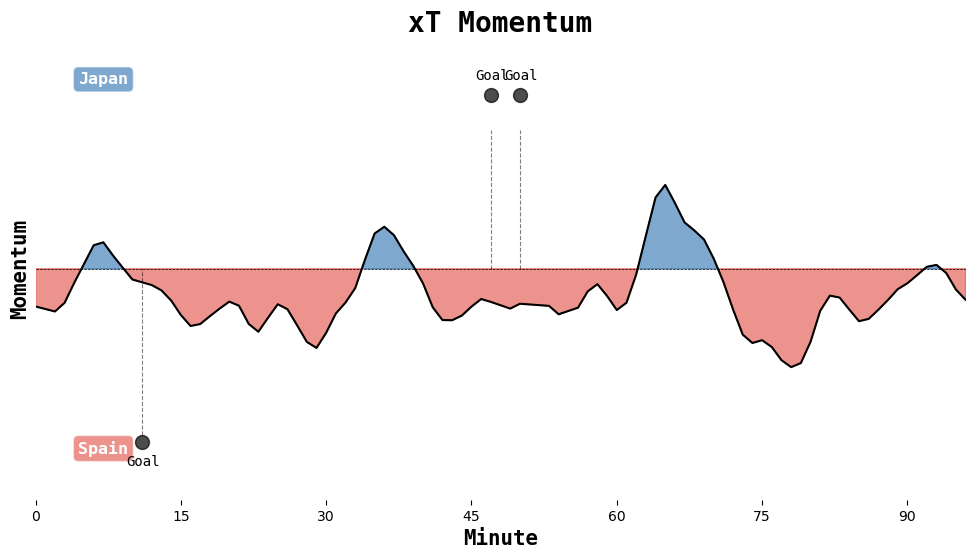

In [30]:
momentum(Test, window_size=4, decay_rate=0.25, sigma=1)

In [31]:
def CumulativeXG(EventData):
    Home_Team, Away_Team = list(EventData['team'].unique())

    df_xg = EventData.groupby(
        ['team', 'minute'], as_index=False
    )['shot_statsbomb_xg'].sum()

    # Create every minute of the match
    max_minute = df_xg['minute'].max()
    
    all_minutes = pd.MultiIndex.from_product(
        [[Home_Team, Away_Team], range(0, max_minute + 1)],
        names=['team', 'minute']
    )

    df_xg = (
        df_xg
        .set_index(['team', 'minute'])
        .reindex(all_minutes, fill_value=0)
        .reset_index()
    )

    # Calculate cumulative xG
    df_xg['cumulative_xg'] = (
        df_xg.groupby('team')['shot_statsbomb_xg'].cumsum()
    )

    fig, ax = plt.subplots(figsize=(12, 6))
    fig.set_facecolor('White')
    ax.set_facecolor('White')

    home_xg = df_xg[df_xg.team == Home_Team]
    away_xg = df_xg[df_xg.team == Away_Team]

    plt.stairs(
        home_xg['cumulative_xg'],
        range(0, max_minute + 2),
        color='#0053a0',
        label=Home_Team
    )

    plt.stairs(
        away_xg['cumulative_xg'],
        range(0, max_minute + 2),
        color='#DA291C',
        label=Away_Team
    )

    ax.set_title(
        "Cumulative xG",
        color='Black',
        fontsize=20,
        fontweight='bold',
        fontfamily='Monospace',
        pad=-5
    )

    ax.set_xlabel(
        'Minute',
        color='Black',
        fontsize=15,
        fontweight='bold',
        fontfamily='Monospace'
    )

    ax.set_ylabel(
        'Total xG',
        color='Black',
        fontsize=15,
        fontweight='bold',
        fontfamily='Monospace'
    )

    plt.xlim(0, max_minute + 1)
    plt.xticks(np.arange(0, max_minute + 1, 15))
    ax.legend()

    plt.show()

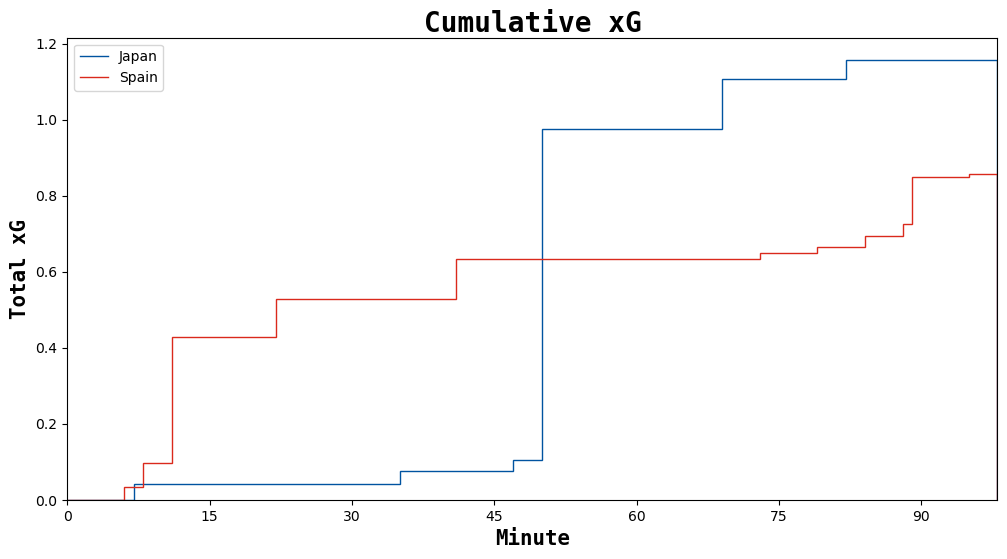

In [32]:
CumulativeXG(Test)

In [86]:
xCords = {"3": [25, 40, 55], "4": [22, 33, 44, 55], "5": [22, 30, 38, 46, 55]}
yCords = {"1": [40], "2": [55, 25], "3": [60, 40, 20], "4": [70, 50, 30, 10], "5": [70, 55, 40, 25, 10]}
pitch_order = {
    # Goalkeeper
    1: 1,

    # Defensive line
    2: 2,   # Right Back
    3: 3,   # Right Center Back
    4: 4,   # Center Back
    5: 5,   # Left Center Back
    6: 6,   # Left Back

    # Wing backs
    7: 1,   # Right Wing Back
    8: 7,   # Left Wing Back

    # Defensive midfield
    9: 2,   # Right DM
    10: 4,  # Center DM
    11: 6,  # Left DM

    # Midfield
    12: 2,  # Right Midfield
    13: 3,  # Right Center Midfield
    14: 4,  # Center Midfield
    15: 5,  # Left Center Midfield
    16: 6,  # Left Midfield

    # Attacking midfield
    18: 2,  # Right AM
    19: 4,  # Center AM
    20: 6,  # Left AM

    # Front line
    17: 1,  # Right Wing
    22: 2,  # Right Center Forward
    23: 3,  # Center Forward
    24: 4,  # Left Center Forward
    21: 5,  # Left Wing
    25: 3   # Secondary Striker
}


def startersVisual(Event_Data, starters):
    pitch = Pitch(pitch_color='grass', line_color='white', stripe=True)
    fig, ax = pitch.draw()
    
    Home_Team, Away_Team = list(Event_Data['team'].unique())
    teamFormations = getTeamFormation(Event_Data)

    for i in [Home_Team, Away_Team]:    
        if i == Home_Team:         
            currFormation = teamFormations['home_formation'].tolist()[0]
        else:
            currFormation = teamFormations['away_formation'].tolist()[0]
        formLen = len(currFormation)
        x_coordinates = xCords[str(formLen)]
        starters["pitch_order"] = starters['position_id'].map(pitch_order)
        players = starters[(starters.Starter == True) & (starters.team == i)].sort_values("position_id").reset_index(drop = True)


        if i == Home_Team:
            jerseyNum = players['jersey_number'][0]
            players = players[1:].reset_index(drop = True)
    
            ax.scatter(12, 40, s=500, color = "red")
            ax.text(12, 40, int(jerseyNum), ha='center', va='center')

            for m in range(0, formLen):
                width = int(currFormation[m])
                y_coordinates = yCords[str(width)]
                
                Numbers = players[:width].sort_values('pitch_order')['jersey_number'].tolist()
                players = players[width:].reset_index(drop = True)

                for n in range(0, width):
                    jerseyNum = Numbers[n]

                    ax.scatter(x_coordinates[m], y_coordinates[n], s=500, color = "red")
                    ax.text(x_coordinates[m], y_coordinates[n], int(jerseyNum), ha='center', va='center')
                
            
        else:
            jerseyNum = players['jersey_number'][0]
            players = players[1:].reset_index(drop = True)
            
            ax.scatter(108, 40, s=500, color = "blue")
            ax.text(108, 40, int(jerseyNum), ha='center', va='center')

            for m in range(0, formLen):
                width = int(currFormation[m])
                y_coordinates = yCords[str(width)]
                
                Numbers = players[:width].sort_values('pitch_order')['jersey_number'].tolist()
                players = players[width:].reset_index(drop = True)

                for n in range(0, width):
                    jerseyNum = Numbers[n]

                    ax.scatter(120 - x_coordinates[m], 80 - y_coordinates[n], s=500, color = "blue")
                    ax.text(120 - x_coordinates[m], 80 - y_coordinates[n], int(jerseyNum), ha='center', va='center')

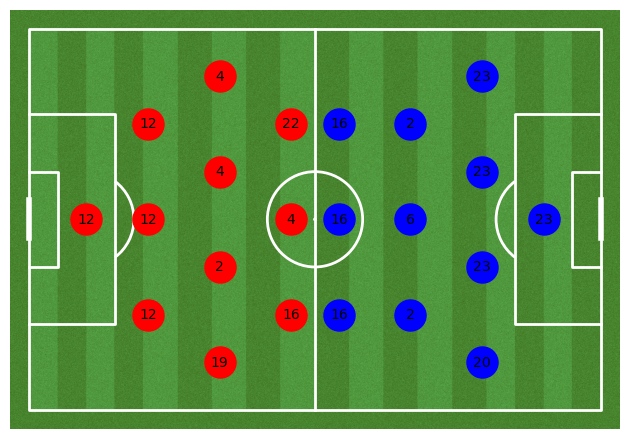

In [90]:
startersVisual(Test, starters_df)

In [35]:
def plotShotsInteractive(Event_Data):
    HOME_TEAM, AWAY_TEAM= list(Event_Data['team'].unique())

    Event_Data[['x', 'y', 'z']] = Event_Data['location'].apply(lambda loc: pd.Series(loc[:3]) if isinstance(loc, list) else pd.Series([None, None, None]))
    Event_Data = Event_Data[['player', 'team', 'shot_outcome', 'shot_body_part', 
                             'x', 'y', 'minute', 'period', 'shot_statsbomb_xg', 'type']]
    Event_Data['shot_statsbomb_xg'] = round(Event_Data['shot_statsbomb_xg'], 2)

    HomeShots = Event_Data[Event_Data.team == HOME_TEAM]
    AwayShots = Event_Data[Event_Data.team == AWAY_TEAM]
    AwayShots['x'] = 120 - AwayShots['x']
    AwayShots['y'] = 80 - AwayShots['y']

    HomeGoals = HomeShots[HomeShots.shot_outcome == "Goal"]
    HomeMisses = HomeShots[(HomeShots.shot_outcome != "Goal") & (HomeShots.type == "Shot")]

    AwayGoals = AwayShots[AwayShots.shot_outcome == "Goal"]
    AwayMisses = AwayShots[(AwayShots.shot_outcome != "Goal") & (AwayShots.type == "Shot")]

    # --- Figure and pitch setup ---
    fig = go.Figure()

    # Pitch outline (StatsBomb-style)
    pitch_shapes = [
        dict(type="rect", x0=0, y0=0, x1=120, y1=80, line=dict(color="black", width=3)),
        dict(type="line", x0=60, y0=0, x1=60, y1=80, line=dict(color="black", width=2)),
        dict(type="circle", x0=60-9.15, y0=40-9.15, x1=60+9.15, y1=40+9.15, line=dict(color="black")),
        dict(type="rect", x0=0, y0=18, x1=18, y1=62, line=dict(color="black")),
        dict(type="rect", x0=102, y0=18, x1=120, y1=62, line=dict(color="black")),
        dict(type="rect", x0=0, y0=30, x1=6, y1=50, line=dict(color="black")),
        dict(type="rect", x0=114, y0=30, x1=120, y1=50, line=dict(color="black")),
    ]

    # Home shots
    fig.add_trace(go.Scatter(
        x=HomeMisses['x'],
        y=HomeMisses['y'],
        mode='markers',
        marker=dict(
            symbol='circle-open',
            size=12,
            color='blue'
        ),
        hoverinfo='text',
        hovertext=[
            f"<b>Player:</b> {row['player']}<br>"
            f"<b>Team:</b> {row['team']}<br>"
            f"<b>Minute:</b> {row['minute']}<br>"
            f"<b>xG:</b> {row['shot_statsbomb_xg']:.2f}<br>"
            f"<b>Outcome:</b> {row['shot_outcome']}"
            for _, row in HomeMisses.iterrows()
        ],
        showlegend=False
    ))
    
    fig.add_trace(go.Scatter(
        x=HomeGoals['x'],
        y=HomeGoals['y'],
        mode='markers',
        marker=dict(
            symbol='circle',
            size=12,
            color='blue'
        ),
        hoverinfo='text',
        hovertext=[
            f"<b>Player:</b> {row['player']}<br>"
            f"<b>Team:</b> {row['team']}<br>"
            f"<b>Minute:</b> {row['minute']}<br>"
            f"<b>xG:</b> {row['shot_statsbomb_xg']:.2f}<br>"
            f"<b>Outcome:</b> {row['shot_outcome']}"
            for _, row in HomeGoals.iterrows()
        ],
        showlegend=False
    ))
    
    fig.add_trace(go.Scatter(
        x=AwayMisses['x'],
        y=AwayMisses['y'],
        mode='markers',
        marker=dict(
            symbol='circle-open',
            size=12,
            color='red'
        ),
        hoverinfo='text',
        hovertext=[
            f"<b>Player:</b> {row['player']}<br>"
            f"<b>Team:</b> {row['team']}<br>"
            f"<b>Minute:</b> {row['minute']}<br>"
            f"<b>xG:</b> {row['shot_statsbomb_xg']:.2f}<br>"
            f"<b>Outcome:</b> {row['shot_outcome']}"
            for _, row in AwayMisses.iterrows()
        ],
        showlegend=False
    ))
    
    fig.add_trace(go.Scatter(
        x=AwayGoals['x'],
        y=AwayGoals['y'],
        mode='markers',
        marker=dict(
            symbol='circle',
            size=12,
            color='red'
        ),
        hoverinfo='text',
        hovertext=[
            f"<b>Player:</b> {row['player']}<br>"
            f"<b>Team:</b> {row['team']}<br>"
            f"<b>Minute:</b> {row['minute']}<br>"
            f"<b>xG:</b> {row['shot_statsbomb_xg']:.2f}<br>"
            f"<b>Outcome:</b> {row['shot_outcome']}"
            for _, row in AwayGoals.iterrows()
        ],
        showlegend=False
    ))

    # --- Layout ---
    fig.update_layout(
        shapes=pitch_shapes,
        title=dict(text=f"{HOME_TEAM} vs {AWAY_TEAM} Shot Map", x=0.5, font=dict(size=24, color="black")),
        xaxis=dict(showgrid=False, visible=False, range=[-2, 122], scaleanchor="y", scaleratio=1),
        yaxis=dict(showgrid=False, visible=False, range=[-2, 82]),
        plot_bgcolor="white",
        paper_bgcolor="white",
        width=950, height=650,

    )

    fig.show()

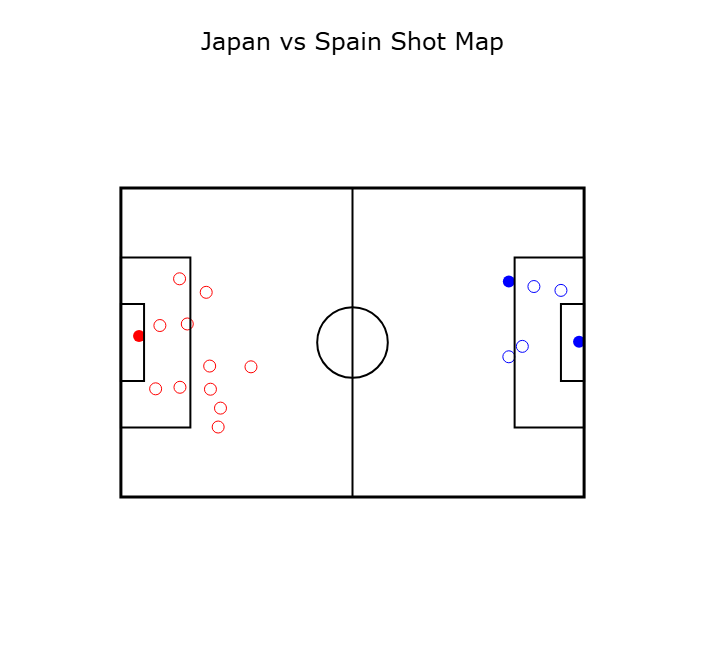

In [36]:
plotShotsInteractive(Test)

In [82]:
def draw_goal(ax):
    post_color="black"
    x1=[44,44]
    y1=[0,2.67]
    ax.plot(x1,y1,c=post_color,linewidth=15,zorder=1)
        
    x2=[36,36]
    y2=[0,2.67]
    ax.plot(x2,y2,c=post_color,linewidth=15,zorder=1)
    
    x3=[44,36]
    y3=[2.67,2.67]
    ax.plot(x3,y3,c=post_color,linewidth=15,zorder=1)
    
    x4=[41.33,41.33]
    y4=[0,2.67]
    ax.plot(x4,y4,c=post_color,linewidth=2.5,zorder=1,linestyle="dashed")

    x5=[38.66,38.66]
    y5=[0,2.67]
    ax.plot(x5,y5,c=post_color,linewidth=2.5,zorder=1,linestyle="dashed")


def plot_pens_SO(data, ax, color, marker):
    if len(data) > 0:
        ax.scatter(
            x=data['end_y'], y=data['end_z'],
            s=1000, marker=marker,
            c=color, ec="white", lw=3,
            alpha=1, zorder=2
        )
        
        # overlay penalty order number inside marker
        for _, row in data.iterrows():
            ax.text(
                row["end_y"], row["end_z"], str(row["order"]),
                color="white", fontsize=14,
                ha="center", va="center", fontweight="bold",
                zorder=3
            )

def generateVisual_SO(Event_Data):
    HOME_TEAM, AWAY_TEAM= list(Event_Data['team'].unique())
    penSO = Event_Data[(Event_Data.period == 5) & (Event_Data.type == 'Shot')]
    penSO[['end_x', 'end_y', 'end_z']] = penSO['shot_end_location'].apply(pd.Series)

    # assign global penalty order (1, 2, 3, …)
    HomePens = penSO[penSO.team == HOME_TEAM].reset_index(drop=True)
    HomePens["order"] = HomePens.index + 1

    AwayPens = penSO[penSO.team == AWAY_TEAM].reset_index(drop=True)
    AwayPens["order"] = AwayPens.index + 1

    # marker/color settings
    marker1="o"   # goal
    marker2="X"   # save
    marker3="D"   # miss
    home_color = "blue"
    away_color = "red"

    # set figure
    fig = plt.figure(figsize=(20,12), constrained_layout=True)
    gs = fig.add_gridspec(nrows=1,ncols=1)
    fig.patch.set_facecolor("#e5e5e5")
    ax1 = fig.add_subplot(gs[0])

    draw_goal(ax1)

    for i in [HomePens, AwayPens]:
        goal = i[i['shot_outcome'] == "Goal"]
        save = i[(i['shot_outcome'] == "Saved") | (i['shot_outcome'] == "Saved to Post")]
        post = i[i['shot_outcome'] == "Post"]
        miss = i[(i['shot_outcome'] == "Wayward") | 
                    (i['shot_outcome'] == "Off T") | 
                    (i['shot_outcome'] == "Saved Off Target")]

        if i is HomePens:
            col = home_color
        else:
            col = away_color
        
        plot_pens_SO(goal, ax1, col, marker1)
        plot_pens_SO(save, ax1, col, marker2)
        plot_pens_SO(miss, ax1, col, marker3)
        plot_pens_SO(post, ax1, col, marker3)

    ax1.set_xlim(34.5,45.5)
    ax1.set_ylim(-0.25,4.5)
    ax1.axis('off')
    
    
    # legend
    custom_markers = [
        Line2D([0], [0], ls="None", color='black', markersize=20, marker=marker1),
        Line2D([0], [0], ls="None", color='black', markersize=20, marker=marker2),
        Line2D([0], [0], ls="None", color='black', markersize=20, marker=marker3),
        Line2D([0], [0], ls="None", color='black', markersize=20, marker=marker3)
    ]
    labels = ["Goal","Save","Miss","Post"]
    fig.legend(custom_markers, labels, fontsize=20,
               bbox_to_anchor=(0.975, 1.125), ncol=4, edgecolor="black")
    # Team color legend
    team_markers = [
        Line2D([0], [0], ls="None", color=home_color, markersize=20, marker="o"),
        Line2D([0], [0], ls="None", color=away_color, markersize=20, marker="o")
    ]
    
    team_labels = [HOME_TEAM, AWAY_TEAM]
    
    fig.legend(
        team_markers, team_labels,
        fontsize=20,
        bbox_to_anchor=(0.975, 1.06),
        ncol=2,
        edgecolor="black"
    )

    
    fig.text(
        s=f"{HOME_TEAM} vs {AWAY_TEAM} \nPenalty Shootout",
        x=0.025, y =1.015, fontsize=36, fontweight="bold"
        )
    

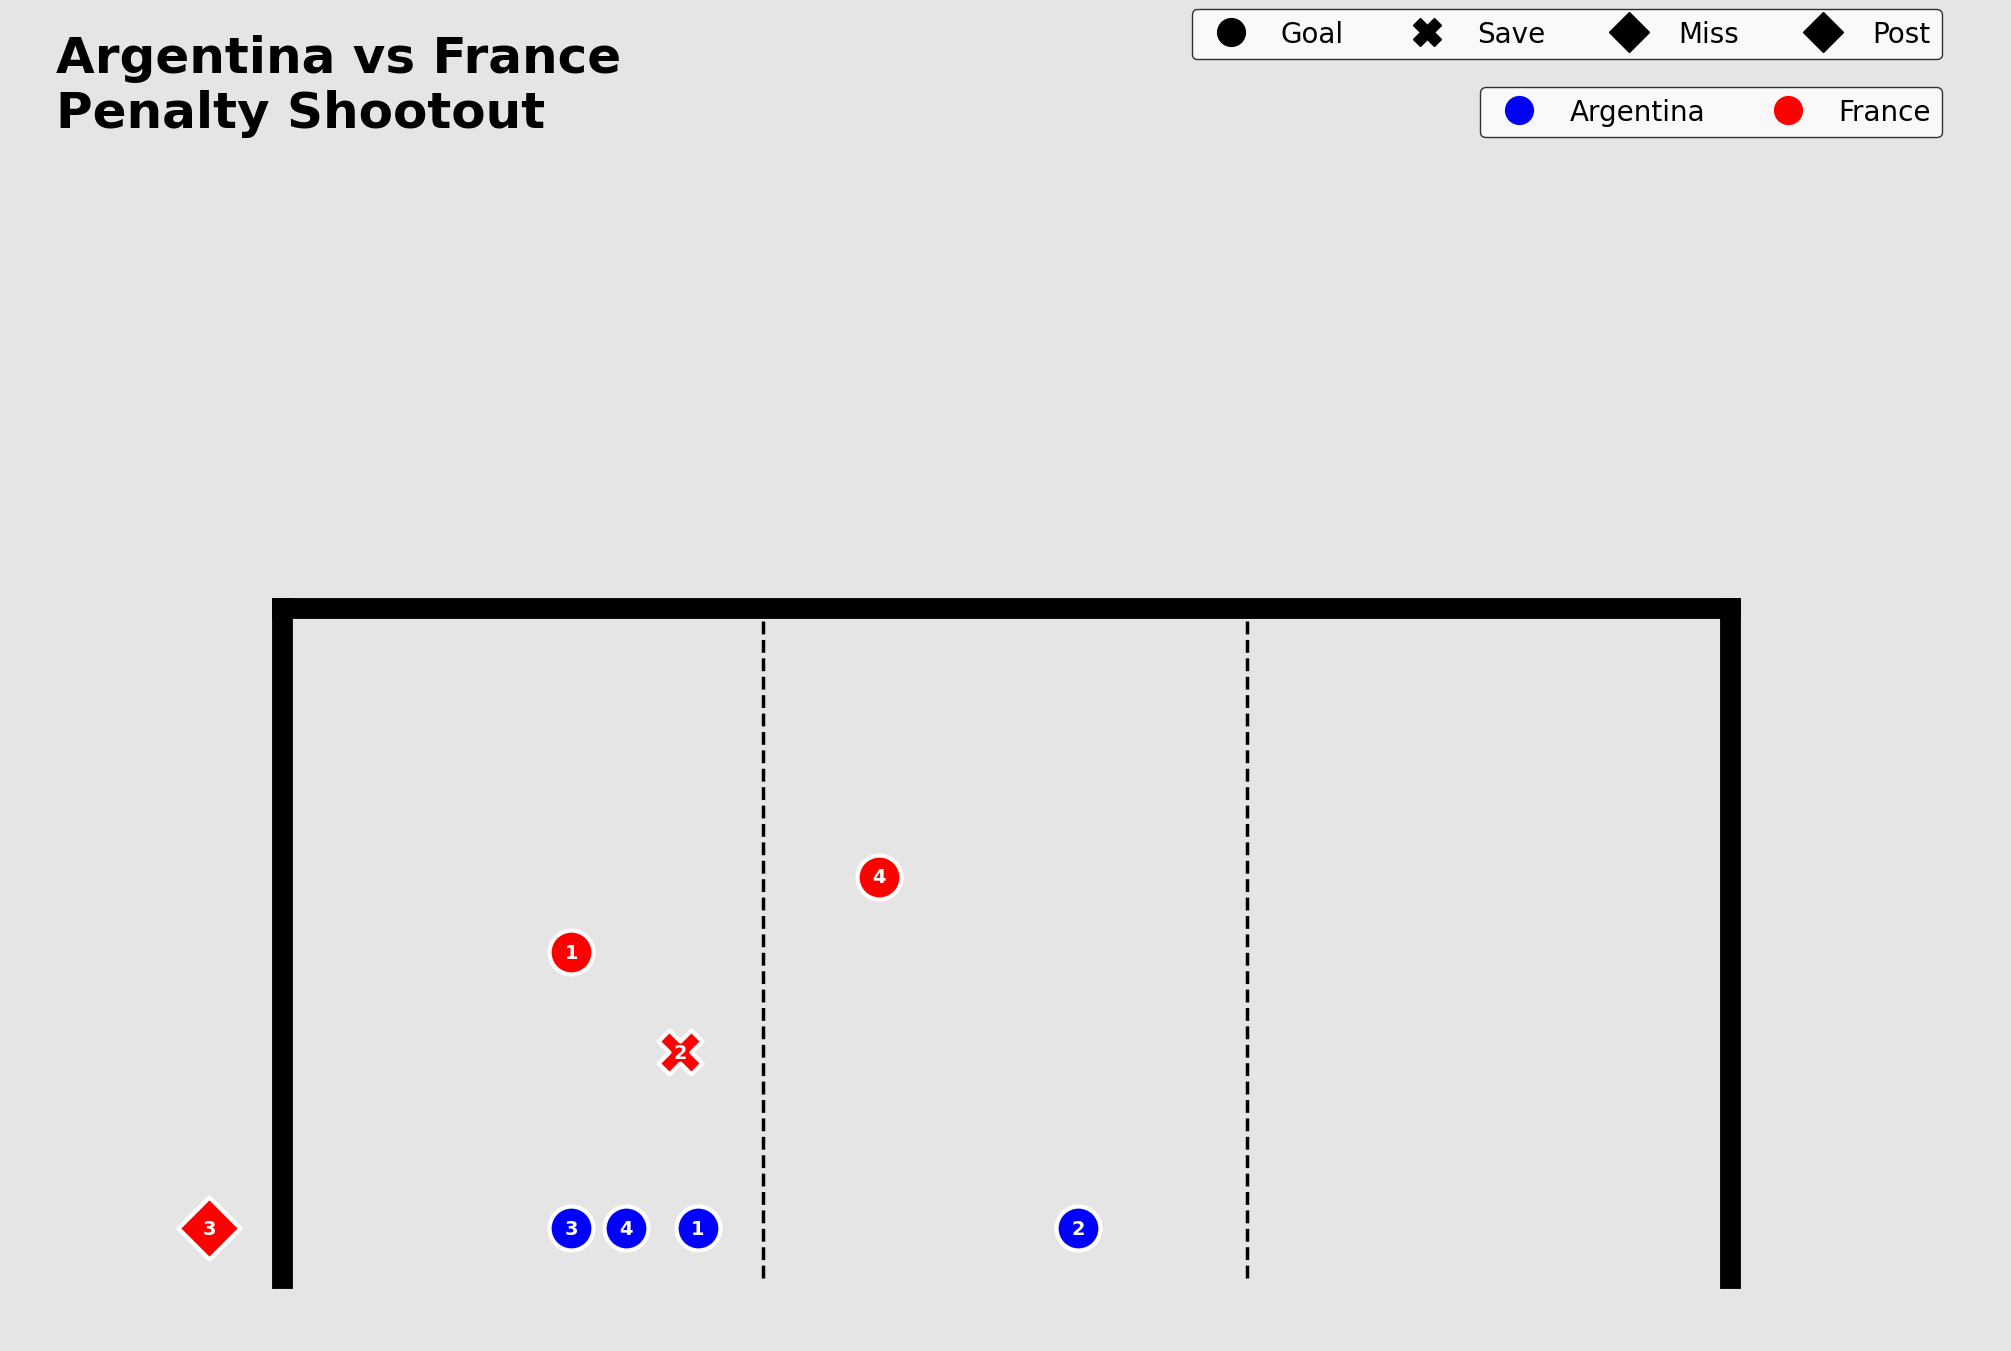

In [83]:
generateVisual_SO(penMatch)

## **Data Exports and Collection**
This section was used to collect the necessary data to export into CSV form. Please note that some CSVs in the repository, such as the name mapping dataset, were gathered by hand using wikipedia or FIFA's official site for the tournament. Please see the read me file in the folder for data for information on where each dataset came from.

## **Get Tournament Data**

In [24]:
matches = sb.matches(43, 106).sort_values("match_date")
matches = matches[['match_id', 'match_date', 'competition', 'season', 'home_team', 'away_team', 'home_score', 'away_score', 
                   'competition_stage', 'stadium', 'home_managers', 'away_managers', 'kick_off']].reset_index(drop = True)
matches['game_classification'] = matches['home_team'].str.upper() + " vs " + matches['away_team'].str.upper()

In [26]:
EventDfs = []
AttackerDfs = []
MidfielderDfs = []
DefenderDfs = []
KeeperDfs = []
StandardDFs = []
TeamDFs = []

for i in matches.match_id:
    print(i)

    currEvents = sb.events(match_id = i)
    EventDfs.append(currEvents)

    TM = getTeamStats(currEvents)
    TeamDFs.append(TM)
    ATT, MID, DEF, GK = getPlayerStats(currEvents, i)
    AttackerDfs.append(ATT)
    MidfielderDfs.append(MID)
    DefenderDfs.append(DEF)
    KeeperDfs.append(GK)
    STAN = getStandardStats(currEvents, i)
    StandardDFs.append(STAN)

Event_Data = pd.concat(EventDfs, axis = 0, ignore_index = True)
Attacker_Data = pd.concat(AttackerDfs, axis = 0, ignore_index = True)
Midfielder_Data = pd.concat(MidfielderDfs, axis = 0, ignore_index = True)
Defender_Data = pd.concat(DefenderDfs, axis = 0, ignore_index = True)
Keeper_Data = pd.concat(KeeperDfs, axis = 0, ignore_index = True)
Standard_Data = pd.concat(StandardDFs, axis = 0, ignore_index = True)
Team_Data = pd.concat(TeamDFs, axis = 0, ignore_index = True)

#Event_Data.to_csv("2022WorldCup_EventData.csv")
Attacker_Data.to_csv("2022WorldCup_AttackerData.csv")
Midfielder_Data.to_csv("2022WorldCup_MidfielderData.csv")
Defender_Data.to_csv("2022WorldCup_DefenderData.csv")
Keeper_Data.to_csv("2022WorldCup_KeeperData.csv")
Standard_Data.to_csv("2022WorldCup_StandardData.csv")
Team_Data.to_csv("TeamStats_WC2022.csv")

3857286
3857271
3857282
3857285
3857254
3857300
3857279
3857265
3857277
3857291
3857268
3857284
3857258
3857290
3857298
3857287
3857273
3857301
3857272
3857274
3857288
3857289
3857266
3857297
3857281
3857283
3857263
3857295
3857299
3857259
3857269
3857270
3857294
3857261
3857278
3857267
3857264
3857275
3857260
3857257
3857276
3857296
3857255
3857292
3857262
3857280
3857293
3857256
3869117
3869151
3869152
3869118
3869253
3869219
3869254
3869220
3869321
3869420
3869486
3869354
3869519
3869552
3869684
3869685


In [39]:
matches = getEndingPeriod(Event_Data, matches)
formations = getTeamFormation(Event_Data)
penMatches = findPenaltyInformation(Event_Data)
matches = pd.merge(matches, formations, how = "left", on = ['match_id', "home_team", "away_team"])
matches = pd.merge(matches, penMatches, how = "left", on = ['match_id', "home_team", "away_team"])
matches

,match_id,match_date,competition,season,home_team,away_team,home_score,away_score,competition_stage,stadium,home_managers,away_managers,kick_off,game_classification,Ending Period,Final,away_formation,home_formation,home_pen_goals,away_pen_goals
0,3857286,2022-11-20,International - FIFA World Cup,2022,Qatar,Ecuador,0,2,Group Stage,Al Bayt Stadium,Félix Sánchez Bas,Gustavo Julio Alfaro,16:00:00.000,QATAR vs ECUADOR,2,Full Time,442,352,NaN,NaN
1,3857271,2022-11-21,International - FIFA World Cup,2022,England,Iran,6,2,Group Stage,Sheikh Khalifa International Stadium,Gareth Southgate,Carlos Manuel Brito Leal Queiróz,13:00:00.000,ENGLAND vs IRAN,2,Full Time,343,4231,NaN,NaN
2,3857282,2022-11-21,International - FIFA World Cup,2022,United States,Wales,1,1,Group Stage,Ahmad bin Ali Stadium,Gregg Berhalter,Robert Page,19:00:00.000,UNITED STATES vs WALES,2,Full Time,352,433,NaN,NaN
3,3857285,2022-11-21,International - FIFA World Cup,2022,Senegal,Netherlands,0,2,Group Stage,Al Thumama Stadium,Aliou Cissé,Louis van Gaal,16:00:00.000,SENEGAL vs NETHERLANDS,2,Full Time,3412,4231,NaN,NaN
4,3857254,2022-11-22,International - FIFA World Cup,2022,Denmark,Tunisia,0,0,Group Stage,Education City Stadium,Kasper Hjulmand,Jalel Kadri,13:00:00.000,DENMARK vs TUNISIA,2,Full Time,343,352,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59,3869354,2022-12-10,International - FIFA World Cup,2022,England,France,1,2,Quarter-finals,Al Bayt Stadium,Gareth Southgate,Didier Deschamps,21:00:00.000,ENGLAND vs FRANCE,2,Full Time,4231,433,NaN,NaN
60,3869519,2022-12-13,International - FIFA World Cup,2022,Argentina,Croatia,3,0,Semi-finals,Lusail Stadium,Lionel Sebastián Scaloni,Zlatko Dalić,21:00:00.000,ARGENTINA vs CROATIA,2,Full Time,433,442,NaN,NaN
61,3869552,2022-12-14,International - FIFA World Cup,2022,France,Morocco,2,0,Semi-finals,Al Bayt Stadium,Didier Deschamps,Hoalid Regragui,21:00:00.000,FRANCE vs MOROCCO,2,Full Time,343,4231,NaN,NaN
62,3869684,2022-12-17,International - FIFA World Cup,2022,Croatia,Morocco,2,1,3rd Place Final,Sheikh Khalifa International Stadium,Zlatko Dalić,Walid Regragui,17:00:00.000,CROATIA vs MOROCCO,2,Full Time,433,4231,NaN,NaN


In [28]:
print("Event IDs:", len(Event_Data.match_id.unique()))
print("Attacker Event IDs:", len(Attacker_Data.game_id.unique()))
print("Midfielder Event IDs:", len(Midfielder_Data.game_id.unique()))
print("Defender Event IDs:", len(Defender_Data.game_id.unique()))
print("Keeper Event IDs:", len(Keeper_Data.game_id.unique()))
print("Standard Event IDs:", len(Standard_Data.game_id.unique()))
print("Team Event IDs:", len(Team_Data.match_id.unique()))

Event IDs: 64
Attacker Event IDs: 64
Midfielder Event IDs: 64
Defender Event IDs: 64
Keeper Event IDs: 64
Standard Event IDs: 64
Team Event IDs: 64


In [89]:
starters_df = getStarters(Event_Data)

In [48]:
mapping = pd.read_csv("PlayerMapping_WC2022.csv")
starters_df = starters_df.merge(mapping, on = 'player', how = 'left')
starters_df

,match_id,player,jersey_number_x,position_id,position,Starter,team_x,jersey_number_y,team_y,player_abbr
0,3857254,Andreas Christensen,6.0,5.0,Left Center Back,True,Denmark,6,Denmark,Andreas Christensen
1,3857254,Simon Thorup Kjær,4.0,4.0,Center Back,True,Denmark,4,Denmark,Simon Kjær
2,3857254,Joachim Andersen,2.0,3.0,Right Center Back,True,Denmark,2,Denmark,Joachim Andersen
3,3857254,Kasper Schmeichel,1.0,1.0,Goalkeeper,True,Denmark,1,Denmark,Kasper Schmeichel
4,3857254,Thomas Delaney,8.0,10.0,Center Defensive Midfield,True,Denmark,8,Denmark,Thomas Delaney
...,...,...,...,...,...,...,...,...,...,...
1990,3869685,Axel Disasi,NaN,NaN,NaN,False,France,3,France,Axel Disasi
1991,3869685,Paulo Bruno Exequiel Dybala,NaN,15.0,Left Center Midfield,False,Argentina,21,Argentina,Paulo Dybala
1992,3869685,Randal Kolo Muani,NaN,17.0,Right Wing,False,France,12,France,Randal Kolo Muani
1993,3869685,Marcus Thuram,NaN,21.0,Left Wing,False,France,26,France,Marcus Thuram


In [49]:
Event_Data.to_csv("2022WorldCup_EventData.csv")
Attacker_Data.to_csv("2022WorldCup_AttckerData.csv")
Midfielder_Data.to_csv("2022WorldCup_MidfielderData.csv")
Defender_Data.to_csv("2022WorldCup_DefenderData.csv")
Keeper_Data.to_csv("2022WorldCup_KeeperData.csv")
matches.to_csv("2022WorldCup_Schedule.csv")
starters_df.to_csv("2022WorldCup_Starters.csv", index=False, encoding="utf-8-sig")

In [59]:
cols = ['team', 'match_id', 'minute', 'player', 'type', 'substitution_replacement']
SubData = Event_Data[Event_Data.type == 'Substitution'][cols]

In [60]:
SubData.to_csv("2022WorldCup_SubEntry.csv")

In [100]:
VisualData = Event_Data[['match_id', 'type', 'team', 'minute', 'period',
                         'second', 'location', 'pass_end_location', 'carry_end_location', 'shot_end_location',
                         'shot_outcome', 'player', 'shot_statsbomb_xg']]
VisualData.to_csv("2022WorldCup_VisualizationData.csv", index = False)

In [114]:
penalty_shots = Event_Data[
    (Event_Data["type"] == "Shot")
    & (Event_Data["shot_type"] == "Penalty")
].copy()

# Extract the related goalkeeper event ID.
penalty_shots["goalkeeper_event_id"] = (
    penalty_shots["related_events"]
    .apply(
        lambda events: events[0]
        if isinstance(events, list) and len(events) > 0
        else None
    )
)

# Keep goalkeeper events and rename fields for the join.
goalkeeper_events = Event_Data[
    Event_Data["type"] == "Goal Keeper"
][["id", "player", "team"]].copy()

goalkeeper_events = goalkeeper_events.rename(
    columns={
        "id": "goalkeeper_event_id",
        "player": "goalkeeper",
        "team": "goalkeeper_team",
    }
)

# Match each penalty to its goalkeeper.
penalty_data = penalty_shots.merge(
    goalkeeper_events,
    on="goalkeeper_event_id",
    how="left",
)

# Create readable labels.
penalty_data["penalty_type"] = np.where(
    penalty_data["period"] == 5,
    "Shootout",
    "In-game",
)

penalty_data["outcome"] = penalty_data["shot_outcome"]

penalty_data = penalty_data[
    [
        "match_id",
        "index",
        "period",
        "minute",
        "second",
        "penalty_type",
        "team",
        "player",
        "goalkeeper",
        "goalkeeper_team",
        "outcome",
        "shot_statsbomb_xg",
        "location",
        "shot_end_location",
    ]
].sort_values(["match_id", "index"])

In [116]:
penalty_data.to_csv("2022WorldCup_PenaltyData.csv", index=False)